# Pandas and exploratory data analysis

COMP 521 · 30-minute introduction, followed by hands-on exploration.

Start with the synthetic table, then use the saved NASA Project 4 snapshot.
Run the examples in order. The **Hands-on exploration** section contains runnable
starter cells to change and investigate; it is ungraded class practice.

## Run this notebook

Use your course Jupyter environment with NumPy, Pandas, and Matplotlib. Either
run inside the course repository, or put this notebook, the saved CSV, and its
`.provenance.json` file together in one folder. Start Jupyter in that folder.
The lecture page links all three downloads. No live archive request is needed.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt

candidates = [Path.cwd() / 'project4-nasa-exoplanets.csv',
              Path.cwd() / 'data/project4-nasa-exoplanets.csv']
candidates += [path / '08-assessments/projects/data/project4-nasa-exoplanets.csv'
               for path in (Path.cwd(), *Path.cwd().parents)]
DATA_FILE = next((path for path in candidates if path.is_file()), None)
if DATA_FILE is None:
    raise FileNotFoundError('Save the lecture CSV beside the notebook, or run inside the course repository')
plt.rcParams.update({'figure.figsize': (6, 4.5), 'figure.dpi': 150,
                     'font.size': 18, 'axes.labelsize': 20,
                     'xtick.labelsize': 17, 'ytick.labelsize': 17,
                     'axes.grid': True, 'grid.alpha': 0.2})

## A labelled table

One row represents one synthetic instrument exposure. The signal uses arbitrary
instrument units; exposure time uses seconds. The quality flag is illustrative.
Index labels identify these rows within this teaching table.

In [2]:
columns = {
    'sample': ['A', 'B', 'C', 'D', 'E'],
    'exposure_s': [1., 2., 2.5, np.nan, 4.],
    'signal': [2., 3., 3., 4., 18.],
    'quality': ['ok', 'ok', 'ok', 'ok', 'flagged']}

In [3]:
row_labels = ['r10', 'r11', 'r12',
              'r13', 'r14']
toy = pd.DataFrame(columns,
                   index=row_labels)
print(toy.to_string())

    sample  exposure_s  signal  quality
r10      A         1.0     2.0       ok
r11      B         2.0     3.0       ok
r12      C         2.5     3.0       ok
r13      D         NaN     4.0       ok
r14      E         4.0    18.0  flagged


In [4]:
print(toy.shape)
print(toy.columns.tolist())
print(toy.index.tolist())

(5, 4)
['sample', 'exposure_s', 'signal', 'quality']
['r10', 'r11', 'r12', 'r13', 'r14']


In [5]:
print(type(toy['signal']).__name__)
print(type(toy[['signal']]).__name__)
print(toy[['sample', 'signal']].to_string())

Series
DataFrame
    sample  signal
r10      A     2.0
r11      B     3.0
r12      C     3.0
r13      D     4.0
r14      E    18.0


In [6]:
print(toy.loc['r10', 'signal'])
print(toy.iloc[0]['signal'])
row = toy.loc['r12', ['sample', 'signal']]
print(row.to_string())

2.0
2.0
sample      C
signal    3.0


In [7]:
print(toy.dtypes.to_string())

sample            str
exposure_s    float64
signal        float64
quality           str


In [8]:
rate = toy['signal'] / toy['exposure_s']
print(rate.to_string())

r10    2.0
r11    1.5
r12    1.2
r13    NaN
r14    4.5


In [9]:
print(toy.isna().sum().to_string())
missing = toy['exposure_s'].isna()
fields = ['sample', 'exposure_s']
unknown = toy.loc[missing, fields]
print(unknown.to_string())

sample        0
exposure_s    1
signal        0
quality       0
    sample  exposure_s
r13      D         NaN


## Select rows with an explicit rule

This illustrative quality rule selects rows for a classroom calculation. It is
not a general prescription for deleting extreme observations.

In [10]:
is_ok = toy['quality'].eq('ok')
print(is_ok.to_string())

r10     True
r11     True
r12     True
r13     True
r14    False


In [11]:
usable = is_ok & toy['exposure_s'].notna()
selected = toy.loc[usable, ['sample', 'exposure_s', 'signal']].copy()
print(selected.to_string())

    sample  exposure_s  signal
r10      A         1.0     2.0
r11      B         2.0     3.0
r12      C         2.5     3.0


## Descriptive summaries

`count` reports available values per column. The 50th percentile is the median.
The mean exposure uses four available values; the mean signal uses five.
Do not interpret these tiny synthetic examples as population estimates.

In [12]:
fields = ['exposure_s', 'signal']
summary = toy[fields].describe()
stats = ['count', 'mean', '50%',
         'min', 'max']
shown = summary.loc[stats].round(3)
print(shown.to_string())

       exposure_s  signal
count       4.000     5.0
mean        2.375     6.0
50%         2.250     3.0
min         1.000     2.0
max         4.000    18.0


In [13]:
print(f"Signal mean: {toy['signal'].mean():.1f}")
print(f"Signal median: {toy['signal'].median():.1f}")
print(f"Exposure count: {toy['exposure_s'].count()}")
print(f"Exposure mean: {toy['exposure_s'].mean():.3f} s")

Signal mean: 6.0
Signal median: 3.0
Exposure count: 4
Exposure mean: 2.375 s


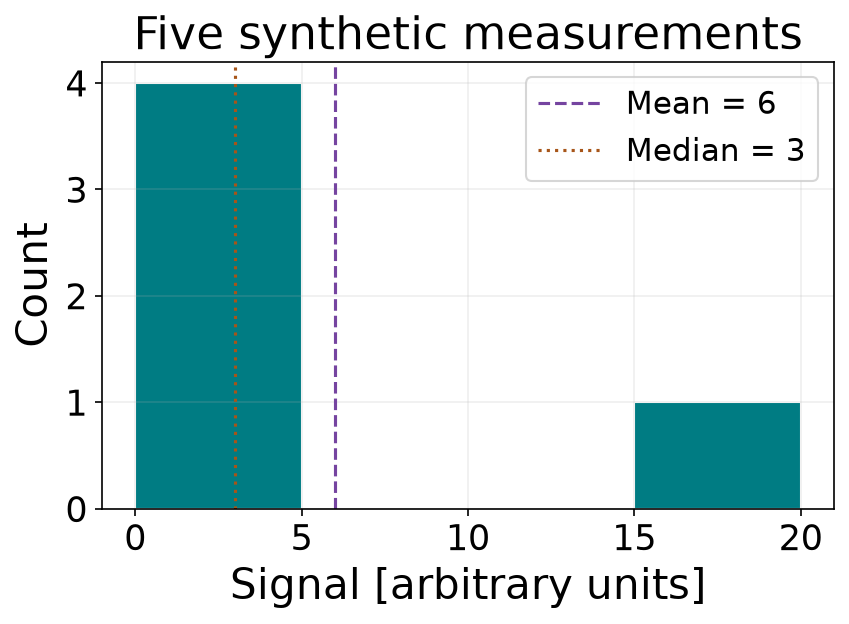

In [14]:
fig, ax = plt.subplots()
ax.hist(toy['signal'], bins=[0, 5, 10, 15, 20], color='#007c83', edgecolor='white')
ax.axvline(toy['signal'].mean(), color='#7544a0', linestyle='--', label='Mean = 6')
ax.axvline(toy['signal'].median(), color='#a75519', linestyle=':', label='Median = 3')
ax.set(xlabel='Signal [arbitrary units]', ylabel='Count', title='Five synthetic measurements')
ax.set_yticks([0, 1, 2, 3, 4])
ax.legend(fontsize=15)
fig.tight_layout()
plt.show()

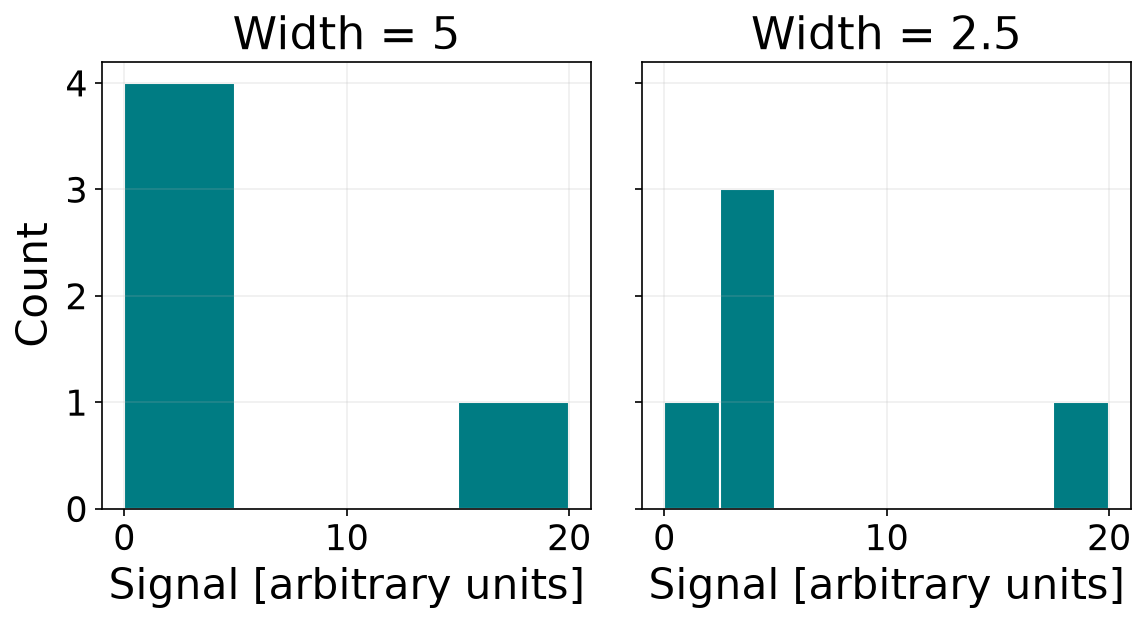

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.5), sharey=True)
for ax, edges, title in zip(axes, ([0, 5, 10, 15, 20], np.linspace(0, 20, 9)),
                             ('Width = 5', 'Width = 2.5')):
    ax.hist(toy['signal'], bins=edges, color='#007c83', edgecolor='white')
    ax.set(xlabel='Signal [arbitrary units]', title=title)
    ax.set_xticks([0, 10, 20])
axes[0].set_ylabel('Count')
fig.tight_layout()
plt.show()

In [16]:
xy = ['exposure_s', 'signal']
paired = toy[xy].notna().all(axis=1)
pairs = toy.loc[paired]
print(pairs.to_string())

    sample  exposure_s  signal  quality
r10      A         1.0     2.0       ok
r11      B         2.0     3.0       ok
r12      C         2.5     3.0       ok
r14      E         4.0    18.0  flagged


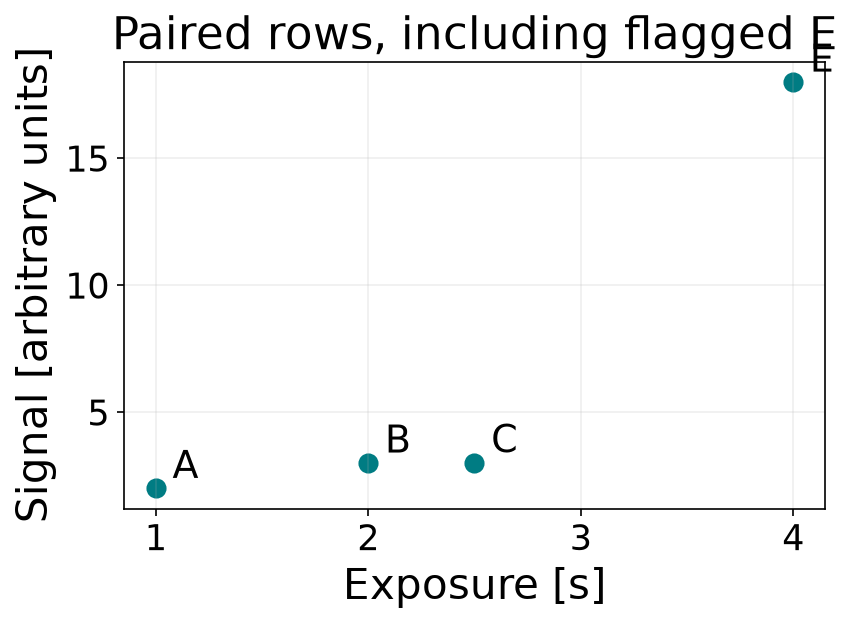

In [17]:
fig, ax = plt.subplots()
ax.scatter(pairs['exposure_s'], pairs['signal'], color='#007c83', s=75)
for _, row in pairs.iterrows():
    ax.annotate(row['sample'], (row['exposure_s'], row['signal']),
                xytext=(8, 5), textcoords='offset points', fontsize=18)
ax.set(xlabel='Exposure [s]', ylabel='Signal [arbitrary units]',
       title='Paired rows, including flagged E')
fig.tight_layout()
plt.show()

## Application: NASA exoplanets

The saved Planetary Systems (`ps`) query supplies default published parameter
sets, not a population-complete sample. It retains names and source references.
Use the public Project 4 query and snapshot provenance.

In [18]:
raw = pd.read_csv(DATA_FILE, comment='#')
print(raw.shape)
print(raw[['pl_name', 'pl_masse', 'pl_rade']].head(4).to_string(index=False))

(437, 15)
     pl_name  pl_masse  pl_rade
TRAPPIST-1 h     0.326    0.755
TRAPPIST-1 d     0.388    0.788
    KOI-55 b     0.440    0.759
   L 98-59 b     0.460    0.837


In [19]:
print(raw[['pl_name', 'pl_masse', 'pl_rade']].dtypes.to_string())

pl_name         str
pl_masse    float64
pl_rade     float64


In [20]:
measure_columns = ['pl_masse', 'pl_masseerr1', 'pl_masseerr2',
                   'pl_rade', 'pl_radeerr1', 'pl_radeerr2']
print(raw[measure_columns].isna().sum().to_string())

pl_masse         0
pl_masseerr1    62
pl_masseerr2    62
pl_rade          0
pl_radeerr1      2
pl_radeerr2      2


In [21]:
finite = np.isfinite(raw[measure_columns]).all(axis=1)
print(f'Six finite fields: {finite.sum()}')

Six finite fields: 375


In [22]:
central = (raw['default_flag'].eq(1)
           & raw['pl_masselim'].eq(0)
           & raw['pl_radelim'].eq(0)
           & raw['pl_bmassprov'].eq('Mass'))
in_window = raw['pl_masse'].between(0.25, 10) & raw['pl_rade'].gt(0)

In [23]:
signed_errors = (raw['pl_masseerr1'].gt(0)
                 & raw['pl_masseerr2'].lt(0)
                 & raw['pl_radeerr1'].gt(0)
                 & raw['pl_radeerr2'].lt(0))

In [24]:
positive_lower = (
    (raw['pl_masse'] + raw['pl_masseerr2']).gt(0)
    & (raw['pl_rade'] + raw['pl_radeerr2']).gt(0))

In [25]:
keep = (finite & central & in_window
        & signed_errors
        & positive_lower)
planets = raw.loc[keep].copy()
print('Input:', len(raw))
print('Selected:', len(planets))
print('Excluded:', len(raw)-len(planets))

Input: 437
Selected: 371
Excluded: 66


In [26]:
summary = planets[['pl_masse', 'pl_rade']].describe()
print(summary.loc[['count', 'mean', '50%', 'min', 'max']].round(3).to_string())

       pl_masse  pl_rade
count   371.000  371.000
mean      5.397    2.231
50%       5.200    2.046
min       0.326    0.736
max      10.000   11.131


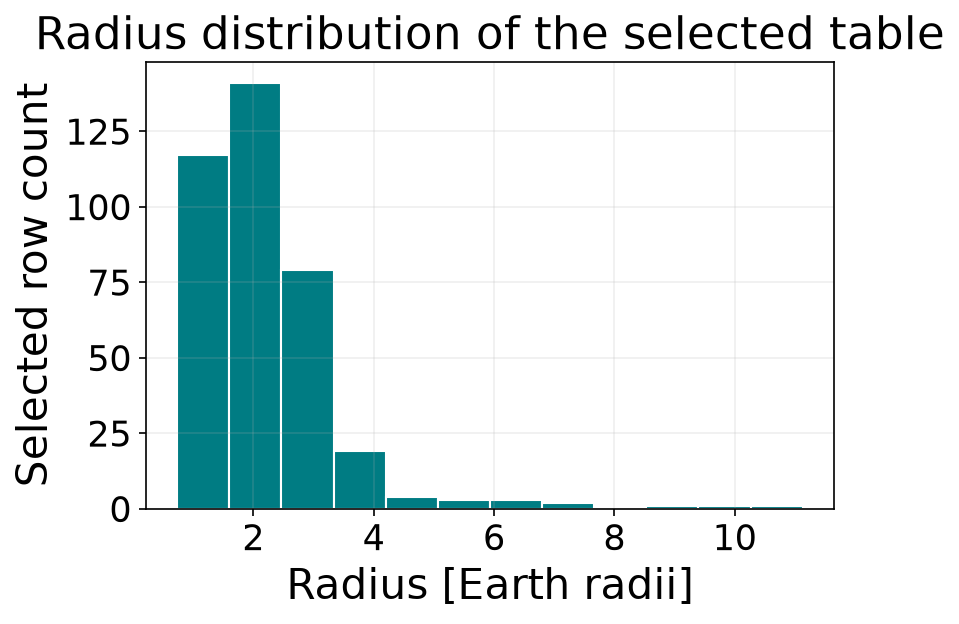

In [27]:
fig, ax = plt.subplots()
counts, edges, _ = ax.hist(planets['pl_rade'], bins=12,
                           color='#007c83', edgecolor='white')
ax.set(xlabel='Radius [Earth radii]', ylabel='Selected row count',
       title='Radius distribution of the selected table')
fig.tight_layout()
plt.show()

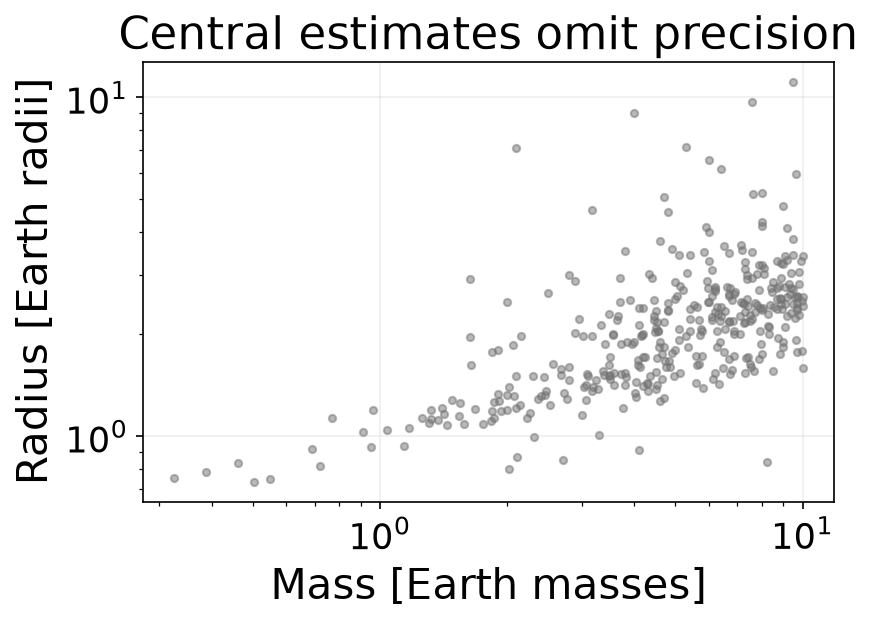

In [28]:
fig, ax = plt.subplots()
ax.scatter(planets['pl_masse'], planets['pl_rade'], s=12, color='0.45', alpha=0.5)
ax.set(xscale='log', yscale='log', xlabel='Mass [Earth masses]',
       ylabel='Radius [Earth radii]', title='Central estimates omit precision')
fig.tight_layout()
plt.show()

## Preserve the published asymmetric offsets

The archive's upper offsets are positive, lower offsets negative. Matplotlib
expects nonnegative lengths in lower/upper rows. Keep all arrays aligned.
Their source studies need not share a confidence level or inference method.

In [29]:
mass_errors = np.vstack((
    -planets['pl_masseerr2'].to_numpy(),
     planets['pl_masseerr1'].to_numpy()))
radius_errors = np.vstack((
    -planets['pl_radeerr2'].to_numpy(),
     planets['pl_radeerr1'].to_numpy()))
print(mass_errors.shape, radius_errors.shape)

(2, 371) (2, 371)


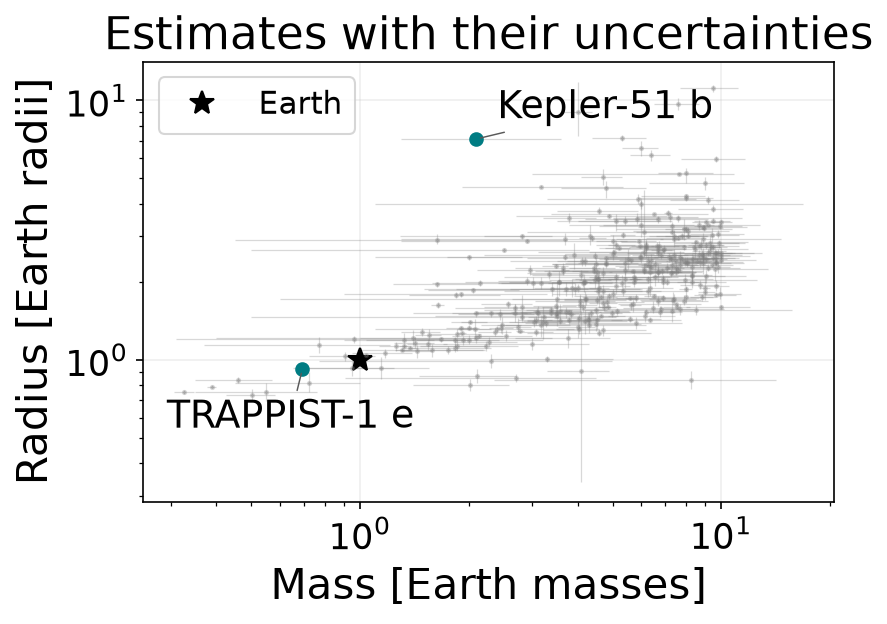

In [30]:
fig, ax = plt.subplots()
ax.errorbar(planets['pl_masse'], planets['pl_rade'],
            xerr=mass_errors, yerr=radius_errors, fmt='.',
            color='0.5', alpha=0.3, markersize=3, elinewidth=0.6)
for name, offset in (('TRAPPIST-1 e', (-65, -28)), ('Kepler-51 b', (10, 10))):
    row = planets.loc[planets['pl_name'].eq(name)].iloc[0]
    ax.plot(row.pl_masse, row.pl_rade, 'o', color='#007c83', zorder=3)
    ax.annotate(name, (row.pl_masse, row.pl_rade), xytext=offset,
                textcoords='offset points', fontsize=18,
                arrowprops={'arrowstyle': '-', 'color': '0.35', 'lw': 0.7})
ax.plot(1, 1, '*', color='black', markersize=12, label='Earth')
ax.set(xscale='log', yscale='log', xlabel='Mass [Earth masses]',
       ylabel='Radius [Earth radii]', title='Estimates with their uncertainties')
ax.legend(fontsize=15)
fig.tight_layout()
plt.show()

In [31]:
kepler = planets.loc[planets['pl_name'].eq('Kepler-51 b')].iloc[0]
lower = kepler.pl_masse + kepler.pl_masseerr2
upper = kepler.pl_masse + kepler.pl_masseerr1
print(f'Mass = {kepler.pl_masse}; interval = [{lower:.1f}, {upper:.1f}] Earth masses')

Mass = 2.1; interval = [1.3, 3.6] Earth masses


In [32]:
assert toy['signal'].mean() == 6 and toy['signal'].median() == 3
assert toy['exposure_s'].count() == 4
assert toy['exposure_s'].mean() == 2.375
assert selected.index.tolist() == ['r10', 'r11', 'r12']
assert pairs.index.tolist() == ['r10', 'r11', 'r12', 'r14']
assert len(raw) == 437 and len(planets) == 371
assert planets['pl_name'].is_unique
assert counts.sum() == len(planets)
assert mass_errors.shape == radius_errors.shape == (2, len(planets))
assert np.all(mass_errors > 0) and np.all(radius_errors > 0)
np.testing.assert_allclose([lower, upper], [1.3, 3.6])
provenance = json.loads(DATA_FILE.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(DATA_FILE.read_bytes()).hexdigest() == provenance['sha256']
print('PASS descriptive arithmetic, row alignment, histogram counts, and P4 uncertainties')

PASS descriptive arithmetic, row alignment, histogram counts, and P4 uncertainties


(hands-on)=
## Hands-on exploration

Work through these tasks after the lecture. The starter cells run as written;
change them, rerun them, and explain the resulting table or plot. Keep the raw
snapshot and `planets` unchanged; use copies named `practice` for experiments.

### Task 1: inspect the snapshot (about 5 minutes)

Run the starter. Add an expression that counts missing values in the six
measurement/error columns. Which field has the most missing entries? Explain
what one row represents and why 437 rows do not imply 437 complete measurements.

In [33]:
print(raw.shape)
print(raw[['pl_name', 'pl_masse', 'pl_rade']].head(4).to_string(index=False))
print(raw[['pl_name', 'pl_masse', 'pl_rade']].dtypes.to_string())

(437, 15)
     pl_name  pl_masse  pl_rade
TRAPPIST-1 h     0.326    0.755
TRAPPIST-1 d     0.388    0.788
    KOI-55 b     0.440    0.759
   L 98-59 b     0.460    0.837
pl_name         str
pl_masse    float64
pl_rade     float64


### Task 2: calculate a labelled column (about 7 minutes)

Run the starter to add `rate` to a copy of the synthetic table. Display only
rows with a known exposure and an `ok` flag. Display only `sample` and `rate`.
Explain why D and E leave this selection for different reasons. Confirm that
`toy` still has its original columns and five rows.

In [34]:
toy_with_rate = toy.copy()
toy_with_rate['rate'] = toy_with_rate['signal'] / toy_with_rate['exposure_s']
print(toy_with_rate.to_string())

    sample  exposure_s  signal  quality  rate
r10      A         1.0     2.0       ok   2.0
r11      B         2.0     3.0       ok   1.5
r12      C         2.5     3.0       ok   1.2
r13      D         NaN     4.0       ok   NaN
r14      E         4.0    18.0  flagged   4.5


### Task 3: change an explicit selection (about 10 minutes)

The starter selects 1–5 Earth masses from the already selected P4 table.
Change the practice window to 2–8 Earth masses, then compare the two counts.
Make the comparison from `planets` each time so narrowing is not cumulative.
Display planet name, mass, and radius. Explain why this changes the table
being described. These are classroom exploration windows, not changes to the
supplied Project 4 selection.

In [35]:
practice = planets.loc[planets['pl_masse'].between(1, 5)].copy()
print(f'P4 rows: {len(planets)}; practice rows: {len(practice)}')
print(practice[['pl_name', 'pl_masse', 'pl_rade']].head().to_string(index=False))

P4 rows: 371; practice rows: 168
     pl_name  pl_masse  pl_rade
TRAPPIST-1 f     1.039    1.045
    K2-157 b     1.140    0.935
  TOI-6324 b     1.170    1.059
TOI-1450 A b     1.258    1.130
TRAPPIST-1 c     1.308    1.097


### Task 4: compare summaries (about 8 minutes)

Run the starter with each practice window from Task 3. Compare count, mean,
median (`50%`), min, and max. Sort `practice` by radius and inspect the five
largest radii, including names and source references. Does a mean alone show
what those records contribute? Describe this selected table without turning
its counts into population occurrence rates.

In [36]:
practice_summary = practice[['pl_masse', 'pl_rade']].describe()
print(practice_summary.loc[['count', 'mean', '50%', 'min', 'max']].round(3).to_string())

       pl_masse  pl_rade
count   168.000  168.000
mean      3.276    1.823
50%       3.480    1.538
min       1.039    0.802
max       5.000    9.000


### Task 5: change the view, then explain it (about 15 minutes)

Run the starter. Change `bins=6` to `bins=12` with the same `practice` table.
Explain what changes and what stays fixed. Try both mass windows and compare
the scatter plots. Each point must use mass and radius from the same row.

Use the `error-arrays` and `nasa-errorbars` reference cells above if you want
to show uncertainties. Rebuild the arrays from `practice`, rather than passing
the full-table arrays to a subset. Describe your selection, the units, and one
limitation of what the plot can tell you. Discuss one result with a neighbor;
there is no new submission.

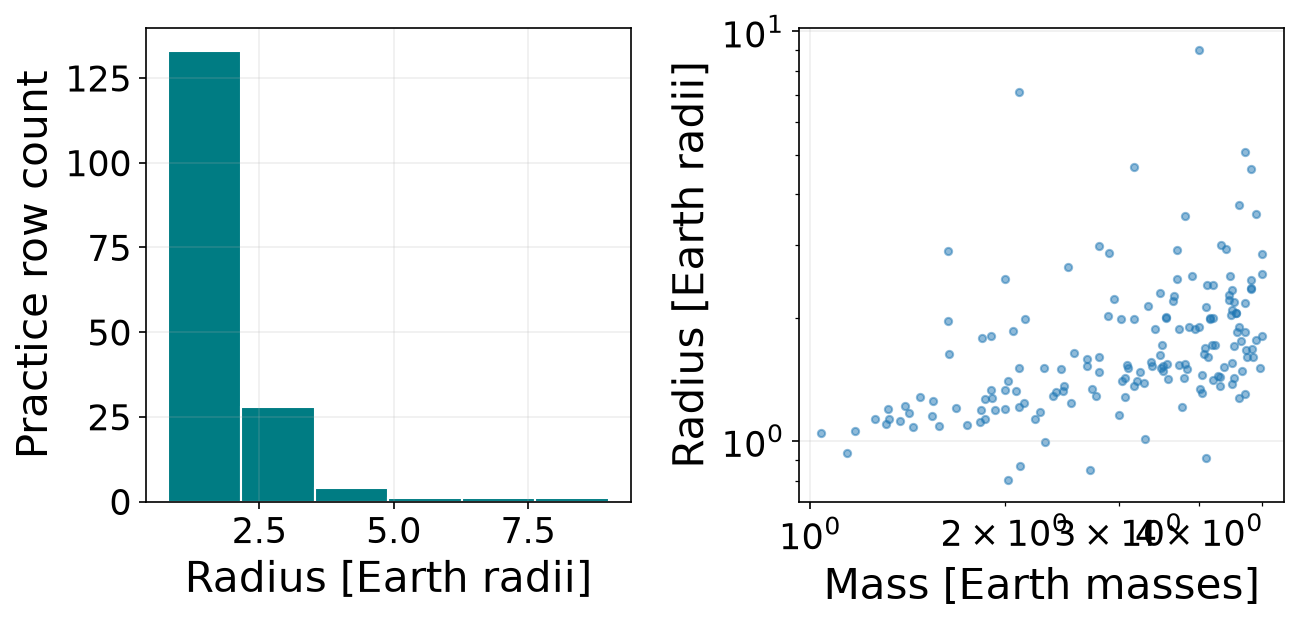

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].hist(practice['pl_rade'], bins=6, color='#007c83', edgecolor='white')
axes[0].set(xlabel='Radius [Earth radii]', ylabel='Practice row count')
axes[1].scatter(practice['pl_masse'], practice['pl_rade'], s=12, alpha=0.5)
axes[1].set(xscale='log', yscale='log',
            xlabel='Mass [Earth masses]', ylabel='Radius [Earth radii]')
fig.tight_layout()
plt.show()